# Exploring Climate and Agricultural Data Using Python

### Project Overview

This project investigates the relationship between environmental conditions and agricultural productivity through exploratory data analysis (EDA). Using publicly available agricultural data from the United States Department of Agriculture (USDA), we will examine historical crop yields, identify trends, and explore geographic differences in agricultural production.

The analysis will initially focus on corn and soybean yields in Iowa and Illinois between 2015 and 2025. As the project progresses, we plan to incorporate environmental datasets from NASA and other public sources to investigate how temperature, precipitation, soil moisture, and other climate variables relate to crop productivity.

This research also supports a broader project initiated during the NASA Space Apps Challenge, which explores how data science can help farmers make informed decisions about crop selection and rotation.

### Research Question

**How do environmental conditions influence corn and soybean yields across counties in Iowa and Illinois, and what patterns can be identified through exploratory data analysis?**

### Objectives

1. Collect, clean, and organize publicly available agricultural datasets.
2. Explore historical crop yields and identify temporal and geographic trends.
3. Investigate relationships between environmental variables and agricultural productivity.
4. Develop statistical visualizations to communicate patterns and findings.
5. Evaluate how these insights could support agricultural decision-making.

### Data Sources

- **USDA National Agricultural Statistics Service (NASS):** Historical crop production, harvested acreage, and yield statistics.
- **NASA Earth Observation Data:** Environmental measurements, including temperature, precipitation, and soil moisture, to be incorporated in later stages.

### Tools and Technologies

- **Python:** Pandas, NumPy, Matplotlib, and Seaborn.
- **Jupyter Notebook:** Data exploration, analysis, visualization, and documentation.
- **R:** Additional data exploration and statistical analysis as part of the broader DAT 301 honors project.

### Scope and Limitations

The initial analysis focuses on county-level agricultural data from two states and two crops. Findings will describe statistical relationships rather than establish causation. Additionally, county-level yield statistics do not provide individual field histories, so the direct effects of crop rotation cannot be determined from this dataset alone.

### Study Area and Crop Selection

This analysis focuses on corn and soybean production in Iowa and Illinois from 2015 to 2025. These states were selected because they are major agricultural producers within the U.S. Corn Belt, where corn–soybean rotation is a common farming practice.

Corn and soybeans were chosen because of their agricultural importance, their different responses to environmental conditions, and their relevance to crop rotation practices. Examining both crops allows us to investigate how factors such as temperature, precipitation, and soil moisture relate to agricultural productivity.

County-level data provides geographic detail for comparing agricultural outcomes across different regions and will allow us to incorporate NASA climate data later in the project.

Limiting the initial analysis to two states and two crops also keeps the dataset manageable while establishing a foundation for potentially expanding the research to additional crops or geographic regions.

**Research Limitation:** The USDA Quick Stats dataset contains aggregated county-level observations rather than individual field histories. Therefore, this analysis can examine environmental relationships with crop yields but cannot directly determine the effects of crop rotation.

### Study Configuration and Reproducibility

To make the data-processing workflow reusable, we will define the study's geographic scope, crop selection, and time period in a centralized configuration.

Separating these settings from the filtering logic allows the same workflow to be adapted to other U.S. states, crops, or study periods without rewriting the underlying code.

Although the current research focuses on Iowa and Illinois from 2015 through 2025, this structure provides a foundation for expanding the analysis to additional regions. International agricultural datasets may require separate processing procedures because their reporting formats and geographic identifiers can differ from USDA standards.

In [2]:
# Study configuration
STUDY_CONFIG = {
    "states": ["IOWA", "ILLINOIS"],
    "crops": ["CORN", "SOYBEANS"],
    "start_year": 2015,
    "end_year": 2025,
    "aggregation_level": "COUNTY",
    "statistic": "YIELD",
    "yield_unit": "BU / ACRE",
}

print("Study configuration:")
for setting, value in STUDY_CONFIG.items():
    print(f"{setting}: {value}")

Study configuration:
states: ['IOWA', 'ILLINOIS']
crops: ['CORN', 'SOYBEANS']
start_year: 2015
end_year: 2025
aggregation_level: COUNTY
statistic: YIELD
yield_unit: BU / ACRE


### Imports and Caching

In [3]:
%pip install matplotlib seaborn pandas requests python-dotenv

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import requests
import hashlib
import json

from dotenv import load_dotenv
from pathlib import Path


Note: you may need to restart the kernel to use updated packages.


In [4]:
# Directory for locally cached USDA API responses
CACHE_DIR = Path("data/cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Cache directory ready: {CACHE_DIR}")

Cache directory ready: data\cache


In [5]:
def get_usda_cache_path(config, counties=None, crop_utilization=None):
    """Create a cache filename based on the query configuration."""
    cache_parameters = {
        "config": config,
        "counties": sorted(counties) if counties is not None else None,
        "crop_utilization": crop_utilization,
        "loader_version": 1,
    }

    cache_key = hashlib.sha256(
        json.dumps(
            cache_parameters,
            sort_keys=True,
            default=str
        ).encode("utf-8")
    ).hexdigest()[:16]

    return CACHE_DIR / f"usda_crop_yields_{cache_key}.pkl"

In [6]:
load_dotenv()

NASS_API_KEY = os.getenv("NASS_API_KEY")

if not NASS_API_KEY:
    raise ValueError(
        "USDA API key not found. "
        "Check that NASS_API_KEY is defined in your .env file."
    )

print("USDA API key loaded successfully.")

USDA API key loaded successfully.


## Reusable Data Processing Functions

The following functions provide a reusable workflow for retrieving, standardizing, and cleaning agricultural yield data from the USDA NASS Quick Stats API.

Separating these operations into functions makes the analysis easier to maintain and allows future studies to change geographic regions, crops, or reporting periods without rewriting the entire notebook.

### USDA Crop Yield Loader

The `load_usda_crop_yields()` function retrieves agricultural yield observations from the USDA NASS Quick Stats API using the parameters defined in `STUDY_CONFIG`.

It applies filters for states, crops, reporting years, geographic aggregation, and yield measurements. Requests are divided into smaller groups to keep individual API responses manageable. The function also supports optional county filtering and crop-specific utilization practices.

### Numeric Yield Conversion

The `convert_usda_yield_to_numeric()` function converts USDA yield measurements into numeric values suitable for statistical analysis.

USDA measurements may contain formatting characters or nonnumeric values. The function removes thousands separators and converts invalid or suppressed values to missing values (`NaN`) so they can be identified during validation.

### Combined-County Exclusion

The `remove_combined_counties()` function optionally removes observations labeled `OTHER (COMBINED) COUNTIES`.

These records represent aggregated geographic areas rather than individual counties. Excluding them prevents ambiguous geographic matches when combining agricultural yields with county-level climate information.

The function retains the option to include these observations in studies where aggregated geographic records are appropriate.

### API Column Standardization

The `standardize_usda_columns()` function standardizes column names returned by the USDA Quick Stats API.

API responses use a different naming convention from the original USDA bulk-download files. Standardizing column names allows the existing cleaning, validation, and exploratory analysis code to work consistently regardless of how the data was retrieved.

In [7]:
# Standardize USDA API column names to match the original TSV format

def standardize_usda_columns(df):
    """Convert USDA API column names to the original TSV naming convention."""
    standardized = df.copy()

    standardized.columns = [
        "CV_%" if col == "CV (%)"
        else col.upper()
        for col in standardized.columns
    ]

    return standardized

In [8]:

def load_usda_crop_yields(
    config,
    api_key,
    counties=None,
    crop_utilization=None,
    force_refresh=False
):
    """
    Retrieve county-level USDA crop yield observations
    using the USDA NASS Quick Stats API.

    Requests are separated by state, crop, and year
    to keep response sizes manageable.

    Cached results are reused unless force_refresh=True.

    Returns
    -------
    pandas.DataFrame
        USDA observations with standardized column names.
    """

    if crop_utilization is None:
        crop_utilization = {
            "CORN": ["GRAIN"],
            "SOYBEANS": ["ALL UTILIZATION PRACTICES"]
        }

    # Determine cache location from the query configuration
    cache_path = get_usda_cache_path(
        config,
        counties=counties,
        crop_utilization=crop_utilization
    )

    # Reuse previously downloaded data when available
    if cache_path.exists() and not force_refresh:
        print(f"Loading cached USDA data from {cache_path}")
        return pd.read_pickle(cache_path)

    api_url = "https://quickstats.nass.usda.gov/api/api_GET/"
    frames = []

    for state in config["states"]:
        for crop in config["crops"]:

            if crop not in crop_utilization:
                raise ValueError(
                    f"No utilization practices configured for {crop}"
                )

            for practice in crop_utilization[crop]:
                for year in range(
                    config["start_year"],
                    config["end_year"] + 1
                ):

                    params = {
                        "key": api_key,
                        "source_desc": "SURVEY",
                        "sector_desc": "CROPS",
                        "commodity_desc": crop,
                        "util_practice_desc": practice,
                        "statisticcat_desc": config["statistic"],
                        "agg_level_desc": config["aggregation_level"],
                        "state_name": state,
                        "year": year,
                        "unit_desc": config["yield_unit"],
                        "domain_desc": "TOTAL",
                        "prodn_practice_desc": "ALL PRODUCTION PRACTICES",
                    }

                    response = requests.get(
                        api_url,
                        params=params,
                        timeout=60
                    )
                    response.raise_for_status()

                    records = response.json().get("data", [])

                    if not records:
                        print(
                            f"No records: {state}, {crop}, {year}"
                        )
                        continue

                    frame = pd.DataFrame(records)
                    frame = standardize_usda_columns(frame)

                    # Preserve FIPS identifiers as strings
                    for column in ["STATE_ANSI", "COUNTY_ANSI"]:
                        if column in frame.columns:
                            frame[column] = frame[column].astype("string")

                    # Match original numeric year format
                    frame["YEAR"] = pd.to_numeric(
                        frame["YEAR"],
                        errors="coerce"
                    )

                    # Optional county filtering
                    if counties is not None:
                        frame = frame[
                            frame["COUNTY_NAME"].isin(counties)
                        ]

                    if not frame.empty:
                        frames.append(frame)

    # Handle queries that return no observations
    if not frames:
        result = pd.DataFrame()
    else:
        result = pd.concat(frames, ignore_index=True)

    # Save the completed API result for future notebook runs
    result.to_pickle(cache_path)
    print(f"Cached USDA data at {cache_path}")

    return result


In [10]:
def convert_usda_yield_to_numeric(df, value_column="VALUE"):
    """
    Convert USDA yield measurements to numeric values.

    Handles comma-separated numbers and converts
    suppressed or invalid values to NaN.

    Returns a new DataFrame without modifying the original.
    """
    cleaned = df.copy()

    cleaned["YIELD"] = pd.to_numeric(
        cleaned[value_column]
        .astype("string")
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="coerce"
    )

    return cleaned

In [11]:
def remove_combined_counties(
    df,
    exclude_combined=True
):
    """
    Optionally exclude USDA combined-county observations.

    These observations represent aggregated geographic areas
    rather than individual counties.

    Parameters
    ----------
    df : pandas.DataFrame
        USDA agricultural observations.

    exclude_combined : bool
        Whether to remove combined-county records.

    Returns
    -------
    pandas.DataFrame
        Cleaned copy of the dataset.
    """

    cleaned = df.copy()

    if exclude_combined:
        combined_mask = (
            cleaned["COUNTY_NAME"]
            .eq("OTHER (COMBINED) COUNTIES")
            .fillna(False)
        )

        cleaned = cleaned.loc[~combined_mask]

    return cleaned.reset_index(drop=True)

In [12]:
# Load the USDA dataset from the API or local cache
crop_preview_source = load_usda_crop_yields(
    config=STUDY_CONFIG,
    api_key=NASS_API_KEY
)

# Select Iowa corn grain yield observations from 2020
df_preview = crop_preview_source.loc[
    (crop_preview_source["STATE_NAME"] == "IOWA")
    & (crop_preview_source["COMMODITY_DESC"] == "CORN")
    & (crop_preview_source["YEAR"] == 2020)
].copy()

print("Preview records:", len(df_preview))
display(df_preview.head())


Loading cached USDA data from data\cache\usda_crop_yields_07b7f9cf3cdcf7f5.pkl
Preview records: 96


,ZIP_5,WATERSHED_CODE,FREQ_DESC,COUNTRY_NAME,VALUE,COUNTY_ANSI,WEEK_ENDING,LOAD_TIME,UTIL_PRACTICE_DESC,STATE_ANSI,...,COUNTY_NAME,STATE_ALPHA,COUNTY_CODE,STATE_FIPS_CODE,ASD_DESC,YEAR,DOMAIN_DESC,WATERSHED_DESC,CLASS_DESC,ASD_CODE
480,,00000000,ANNUAL,UNITED STATES,183.9,021,,2024-02-23 15:00:00.000,GRAIN,19,...,BUENA VISTA,IA,021,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
481,,00000000,ANNUAL,UNITED STATES,185.7,035,,2024-02-23 15:00:00.000,GRAIN,19,...,CHEROKEE,IA,035,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
482,,00000000,ANNUAL,UNITED STATES,168.1,041,,2024-02-23 15:00:00.000,GRAIN,19,...,CLAY,IA,041,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
483,,00000000,ANNUAL,UNITED STATES,182.2,059,,2024-02-23 15:00:00.000,GRAIN,19,...,DICKINSON,IA,059,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
484,,00000000,ANNUAL,UNITED STATES,186.1,063,,2024-02-23 15:00:00.000,GRAIN,19,...,EMMET,IA,063,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10


In [13]:

print("Preview records:", len(df_preview))

print("\nFirst five column names:")
print(df_preview.columns[:5].tolist())


Preview records: 96

First five column names:
['ZIP_5', 'WATERSHED_CODE', 'FREQ_DESC', 'COUNTRY_NAME', 'VALUE']


In [14]:
df_preview = standardize_usda_columns(df_preview)

print("Standardized columns:")
print(df_preview.columns.tolist())

display(df_preview.head())

Standardized columns:
['ZIP_5', 'WATERSHED_CODE', 'FREQ_DESC', 'COUNTRY_NAME', 'VALUE', 'COUNTY_ANSI', 'WEEK_ENDING', 'LOAD_TIME', 'UTIL_PRACTICE_DESC', 'STATE_ANSI', 'STATISTICCAT_DESC', 'AGG_LEVEL_DESC', 'BEGIN_CODE', 'REFERENCE_PERIOD_DESC', 'STATE_NAME', 'COMMODITY_DESC', 'DOMAINCAT_DESC', 'UNIT_DESC', 'CV_%', 'GROUP_DESC', 'PRODN_PRACTICE_DESC', 'SECTOR_DESC', 'LOCATION_DESC', 'CONGR_DISTRICT_CODE', 'REGION_DESC', 'END_CODE', 'SOURCE_DESC', 'COUNTRY_CODE', 'SHORT_DESC', 'COUNTY_NAME', 'STATE_ALPHA', 'COUNTY_CODE', 'STATE_FIPS_CODE', 'ASD_DESC', 'YEAR', 'DOMAIN_DESC', 'WATERSHED_DESC', 'CLASS_DESC', 'ASD_CODE']


,ZIP_5,WATERSHED_CODE,FREQ_DESC,COUNTRY_NAME,VALUE,COUNTY_ANSI,WEEK_ENDING,LOAD_TIME,UTIL_PRACTICE_DESC,STATE_ANSI,...,COUNTY_NAME,STATE_ALPHA,COUNTY_CODE,STATE_FIPS_CODE,ASD_DESC,YEAR,DOMAIN_DESC,WATERSHED_DESC,CLASS_DESC,ASD_CODE
480,,00000000,ANNUAL,UNITED STATES,183.9,021,,2024-02-23 15:00:00.000,GRAIN,19,...,BUENA VISTA,IA,021,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
481,,00000000,ANNUAL,UNITED STATES,185.7,035,,2024-02-23 15:00:00.000,GRAIN,19,...,CHEROKEE,IA,035,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
482,,00000000,ANNUAL,UNITED STATES,168.1,041,,2024-02-23 15:00:00.000,GRAIN,19,...,CLAY,IA,041,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
483,,00000000,ANNUAL,UNITED STATES,182.2,059,,2024-02-23 15:00:00.000,GRAIN,19,...,DICKINSON,IA,059,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
484,,00000000,ANNUAL,UNITED STATES,186.1,063,,2024-02-23 15:00:00.000,GRAIN,19,...,EMMET,IA,063,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10


In [15]:
# Preview the standardized USDA Quick Stats API data

print("Preview dimensions:", df_preview.shape)

print("\nAvailable columns:")
print(df_preview.columns.tolist())

display(df_preview.head())

Preview dimensions: (96, 39)

Available columns:
['ZIP_5', 'WATERSHED_CODE', 'FREQ_DESC', 'COUNTRY_NAME', 'VALUE', 'COUNTY_ANSI', 'WEEK_ENDING', 'LOAD_TIME', 'UTIL_PRACTICE_DESC', 'STATE_ANSI', 'STATISTICCAT_DESC', 'AGG_LEVEL_DESC', 'BEGIN_CODE', 'REFERENCE_PERIOD_DESC', 'STATE_NAME', 'COMMODITY_DESC', 'DOMAINCAT_DESC', 'UNIT_DESC', 'CV_%', 'GROUP_DESC', 'PRODN_PRACTICE_DESC', 'SECTOR_DESC', 'LOCATION_DESC', 'CONGR_DISTRICT_CODE', 'REGION_DESC', 'END_CODE', 'SOURCE_DESC', 'COUNTRY_CODE', 'SHORT_DESC', 'COUNTY_NAME', 'STATE_ALPHA', 'COUNTY_CODE', 'STATE_FIPS_CODE', 'ASD_DESC', 'YEAR', 'DOMAIN_DESC', 'WATERSHED_DESC', 'CLASS_DESC', 'ASD_CODE']


,ZIP_5,WATERSHED_CODE,FREQ_DESC,COUNTRY_NAME,VALUE,COUNTY_ANSI,WEEK_ENDING,LOAD_TIME,UTIL_PRACTICE_DESC,STATE_ANSI,...,COUNTY_NAME,STATE_ALPHA,COUNTY_CODE,STATE_FIPS_CODE,ASD_DESC,YEAR,DOMAIN_DESC,WATERSHED_DESC,CLASS_DESC,ASD_CODE
480,,00000000,ANNUAL,UNITED STATES,183.9,021,,2024-02-23 15:00:00.000,GRAIN,19,...,BUENA VISTA,IA,021,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
481,,00000000,ANNUAL,UNITED STATES,185.7,035,,2024-02-23 15:00:00.000,GRAIN,19,...,CHEROKEE,IA,035,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
482,,00000000,ANNUAL,UNITED STATES,168.1,041,,2024-02-23 15:00:00.000,GRAIN,19,...,CLAY,IA,041,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
483,,00000000,ANNUAL,UNITED STATES,182.2,059,,2024-02-23 15:00:00.000,GRAIN,19,...,DICKINSON,IA,059,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
484,,00000000,ANNUAL,UNITED STATES,186.1,063,,2024-02-23 15:00:00.000,GRAIN,19,...,EMMET,IA,063,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10


In [16]:
# Inspect the structure of the USDA dataset
df_preview.info()

# Check for missing values
print("\nMissing Values:")
print(df_preview.isnull().sum())

# Display the first 10 rows
display(df_preview.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 480 to 575
Data columns (total 39 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   ZIP_5                  96 non-null     str   
 1   WATERSHED_CODE         96 non-null     str   
 2   FREQ_DESC              96 non-null     str   
 3   COUNTRY_NAME           96 non-null     str   
 4   VALUE                  96 non-null     str   
 5   COUNTY_ANSI            96 non-null     string
 6   WEEK_ENDING            96 non-null     str   
 7   LOAD_TIME              96 non-null     str   
 8   UTIL_PRACTICE_DESC     96 non-null     str   
 9   STATE_ANSI             96 non-null     string
 10  STATISTICCAT_DESC      96 non-null     str   
 11  AGG_LEVEL_DESC         96 non-null     str   
 12  BEGIN_CODE             96 non-null     str   
 13  REFERENCE_PERIOD_DESC  96 non-null     str   
 14  STATE_NAME             96 non-null     str   
 15  COMMODITY_DESC         96 non-nul

,ZIP_5,WATERSHED_CODE,FREQ_DESC,COUNTRY_NAME,VALUE,COUNTY_ANSI,WEEK_ENDING,LOAD_TIME,UTIL_PRACTICE_DESC,STATE_ANSI,...,COUNTY_NAME,STATE_ALPHA,COUNTY_CODE,STATE_FIPS_CODE,ASD_DESC,YEAR,DOMAIN_DESC,WATERSHED_DESC,CLASS_DESC,ASD_CODE
480,,00000000,ANNUAL,UNITED STATES,183.9,021,,2024-02-23 15:00:00.000,GRAIN,19,...,BUENA VISTA,IA,021,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
481,,00000000,ANNUAL,UNITED STATES,185.7,035,,2024-02-23 15:00:00.000,GRAIN,19,...,CHEROKEE,IA,035,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
482,,00000000,ANNUAL,UNITED STATES,168.1,041,,2024-02-23 15:00:00.000,GRAIN,19,...,CLAY,IA,041,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
483,,00000000,ANNUAL,UNITED STATES,182.2,059,,2024-02-23 15:00:00.000,GRAIN,19,...,DICKINSON,IA,059,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
484,,00000000,ANNUAL,UNITED STATES,186.1,063,,2024-02-23 15:00:00.000,GRAIN,19,...,EMMET,IA,063,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
485,,00000000,ANNUAL,UNITED STATES,197,119,,2024-02-23 15:00:00.000,GRAIN,19,...,LYON,IA,119,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
486,,00000000,ANNUAL,UNITED STATES,199.5,141,,2024-02-23 15:00:00.000,GRAIN,19,...,O BRIEN,IA,141,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
487,,00000000,ANNUAL,UNITED STATES,185.3,143,,2024-02-23 15:00:00.000,GRAIN,19,...,OSCEOLA,IA,143,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
488,,00000000,ANNUAL,UNITED STATES,181.1,147,,2024-02-23 15:00:00.000,GRAIN,19,...,PALO ALTO,IA,147,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10
489,,00000000,ANNUAL,UNITED STATES,186.2,151,,2024-02-23 15:00:00.000,GRAIN,19,...,POCAHONTAS,IA,151,19,NORTHWEST,2020,TOTAL,,ALL CLASSES,10


In [17]:
# Explore the categories available in the USDA source data

print("Crops:")
print(df_preview["COMMODITY_DESC"].value_counts().head(20))

print("\nStatistic Categories:")
print(df_preview["STATISTICCAT_DESC"].value_counts())

print("\nGeographic Levels:")
print(df_preview["AGG_LEVEL_DESC"].value_counts())

print("\nYears:")
print(df_preview["YEAR"].value_counts().sort_index())

Crops:
COMMODITY_DESC
CORN    96
Name: count, dtype: int64

Statistic Categories:
STATISTICCAT_DESC
YIELD    96
Name: count, dtype: int64

Geographic Levels:
AGG_LEVEL_DESC
COUNTY    96
Name: count, dtype: int64

Years:
YEAR
2020    96
Name: count, dtype: int64


## Data Dictionary

The USDA NASS Quick Stats API returns agricultural observations with descriptive fields covering geographic location, commodity classification, production practices, reporting periods, and measured values.

To document the structure of the source data, we examine the columns returned by our initial API request and construct a data dictionary describing their meanings, data types, and missing-value counts.

Our initial preview contains 96 county-level corn grain yield observations from Iowa in 2020, with 39 available columns.

The missing-value counts in this data dictionary describe only the initial API sample, not the complete agricultural dataset. The full study dataset is retrieved separately using `load_usda_crop_yields()`.


In [18]:
data_dictionary = {
    "SOURCE_DESC": "Source of the data (Census or Survey)",
    "SECTOR_DESC": "Agricultural sector",
    "GROUP_DESC": "Agricultural commodity group",
    "COMMODITY_DESC": "Crop or agricultural commodity",
    "CLASS_DESC": "Classification or variety of the commodity",
    "PRODN_PRACTICE_DESC": "Production practice, such as irrigated or organic",
    "UTIL_PRACTICE_DESC": "How the agricultural commodity is used",
    "STATISTICCAT_DESC": "Type of statistic, such as yield or production",
    "UNIT_DESC": "Measurement unit associated with the value",
    "SHORT_DESC": "Detailed description of the agricultural statistic",
    "DOMAIN_DESC": "Population or category represented by the observation",
    "DOMAINCAT_DESC": "Specific category within the domain",
    "AGG_LEVEL_DESC": "Geographic aggregation level",

    "STATE_ANSI": "State ANSI geographic identifier",
    "STATE_FIPS_CODE": "State FIPS geographic identifier",
    "STATE_ALPHA": "Two-letter state abbreviation",
    "STATE_NAME": "Full state name",
    "ASD_CODE": "Agricultural Statistics District code",
    "ASD_DESC": "Agricultural Statistics District description",
    "COUNTY_ANSI": "County ANSI geographic identifier",
    "COUNTY_CODE": "County geographic code",
    "COUNTY_NAME": "County name",
    "REGION_DESC": "Description of a multi-state region",
    "ZIP_5": "Five-digit ZIP code",
    "WATERSHED_CODE": "Watershed geographic identifier",
    "WATERSHED_DESC": "Watershed description",
    "CONGR_DISTRICT_CODE": "Congressional district code",
    "COUNTRY_CODE": "Country geographic identifier",
    "COUNTRY_NAME": "Country name",
    "LOCATION_DESC": "Full geographic location description",

    "YEAR": "Year associated with the observation",
    "FREQ_DESC": "Reporting frequency, such as annual or weekly",
    "BEGIN_CODE": "Beginning period code",
    "END_CODE": "Ending period code",
    "REFERENCE_PERIOD_DESC": "Reference period for the observation",
    "WEEK_ENDING": "Ending date for weekly observations",
    "LOAD_TIME": "Date and time the record was loaded into USDA Quick Stats",

    "VALUE": "Reported agricultural statistic",
    "CV_%": "Coefficient of variation expressed as a percentage"
}

dictionary_df = pd.DataFrame({
    "Column": df_preview.columns,
    "Description": [
        data_dictionary.get(col, "Description unavailable")
        for col in df_preview.columns
    ],
    "Data Type": df_preview.dtypes.astype(str).values,
    "Missing Values": df_preview.isnull().sum().values
})

display(dictionary_df)

,Column,Description,Data Type,Missing Values
0,ZIP_5,Five-digit ZIP code,str,0
1,WATERSHED_CODE,Watershed geographic identifier,str,0
2,FREQ_DESC,"Reporting frequency, such as annual or weekly",str,0
3,COUNTRY_NAME,Country name,str,0
4,VALUE,Reported agricultural statistic,str,0
5,COUNTY_ANSI,County ANSI geographic identifier,string,0
6,WEEK_ENDING,Ending date for weekly observations,str,0
7,LOAD_TIME,Date and time the record was loaded into USDA ...,str,0
8,UTIL_PRACTICE_DESC,How the agricultural commodity is used,str,0
9,STATE_ANSI,State ANSI geographic identifier,string,0


In [ ]:
from pathlib import Path

# Create shared data dictionary directory
DICTIONARY_DIR = Path("data/dictionaries")
DICTIONARY_DIR.mkdir(parents=True, exist_ok=True)

# Export the USDA data dictionary
DATA_DICTIONARY_PATH = DICTIONARY_DIR / "USDA_Data_Dictionary.csv"

dictionary_df.to_csv(DATA_DICTIONARY_PATH, index=False)

print(f"Data dictionary saved to: {DATA_DICTIONARY_PATH}")

Data dictionary saved to: USDA_Data_Dictionary.csv


In [20]:
# Load USDA crop yields using the Quick Stats API

crop_df = load_usda_crop_yields(
    config=STUDY_CONFIG,
    api_key=NASS_API_KEY
)

print(f"Filtered records: {len(crop_df):,}")

# Verify the crops included
print("\nRecords by crop:")
print(crop_df["COMMODITY_DESC"].value_counts())

# Preview the retrieved data
display(crop_df.head())

Loading cached USDA data from data\cache\usda_crop_yields_07b7f9cf3cdcf7f5.pkl
Filtered records: 3,888

Records by crop:
COMMODITY_DESC
CORN        1963
SOYBEANS    1925
Name: count, dtype: int64


,ZIP_5,WATERSHED_CODE,FREQ_DESC,COUNTRY_NAME,VALUE,COUNTY_ANSI,WEEK_ENDING,LOAD_TIME,UTIL_PRACTICE_DESC,STATE_ANSI,...,COUNTY_NAME,STATE_ALPHA,COUNTY_CODE,STATE_FIPS_CODE,ASD_DESC,YEAR,DOMAIN_DESC,WATERSHED_DESC,CLASS_DESC,ASD_CODE
0,,00000000,ANNUAL,UNITED STATES,202.7,021,,2016-02-18 15:04:50.000,GRAIN,19,...,BUENA VISTA,IA,021,19,NORTHWEST,2015,TOTAL,,ALL CLASSES,10
1,,00000000,ANNUAL,UNITED STATES,209.6,035,,2016-02-18 15:04:50.000,GRAIN,19,...,CHEROKEE,IA,035,19,NORTHWEST,2015,TOTAL,,ALL CLASSES,10
2,,00000000,ANNUAL,UNITED STATES,202.8,041,,2016-02-18 15:04:50.000,GRAIN,19,...,CLAY,IA,041,19,NORTHWEST,2015,TOTAL,,ALL CLASSES,10
3,,00000000,ANNUAL,UNITED STATES,194.5,059,,2016-02-18 15:04:50.000,GRAIN,19,...,DICKINSON,IA,059,19,NORTHWEST,2015,TOTAL,,ALL CLASSES,10
4,,00000000,ANNUAL,UNITED STATES,203.3,063,,2016-02-18 15:04:50.000,GRAIN,19,...,EMMET,IA,063,19,NORTHWEST,2015,TOTAL,,ALL CLASSES,10


## Data Cleaning and Validation

After applying our reusable USDA Quick Stats loader, we have identified **3,888 county-level corn grain and soybean yield observations** from Iowa and Illinois between 2015 and 2025.

The filtered dataset contains 1,963 corn grain observations and 1,925 soybean observations.

Before beginning our exploratory data analysis, we need to ensure the data is accurate, consistent, and suitable for statistical analysis.

In this section, we will:

- Convert reported crop yield values into a numeric format.
- Identify missing or suppressed observations.
- Examine crop classifications and data sources.
- Identify duplicate county-year-crop combinations.
- Exclude combined-county observations that cannot be reliably matched to individual geographic locations.
- Generate descriptive statistics to identify patterns and potential outliers.

These steps will help us prepare a reliable dataset for investigating agricultural productivity and its relationship with environmental conditions.

Our cleaning process will also be designed for reusability, allowing the same validation procedures to be applied to future USDA Quick Stats datasets.

In [21]:
# Examine crop classifications and data sources
# in the filtered USDA dataset

classification_columns = [
    "CLASS_DESC",
    "SHORT_DESC",
    "SOURCE_DESC"
]

for col in classification_columns:
    if col in crop_df.columns:
        print(f"\n{'=' * 50}")
        print(col)
        print("=" * 50)
        print(crop_df[col].value_counts(dropna=False).to_string())
    else:
        print(f"Column not found: {col}")


CLASS_DESC
CLASS_DESC
ALL CLASSES    3888

SHORT_DESC
SHORT_DESC
CORN, GRAIN - YIELD, MEASURED IN BU / ACRE    1963
SOYBEANS - YIELD, MEASURED IN BU / ACRE       1925

SOURCE_DESC
SOURCE_DESC
SURVEY    3888


In [22]:
# Validate the filtered USDA dataset

print(f"Total observations: {len(crop_df):,}")

print("\nRecords by crop:")
print(crop_df["COMMODITY_DESC"].value_counts())

print("\nRecords by state:")
print(crop_df["STATE_NAME"].value_counts())

print("\nYear range:")
print(crop_df["YEAR"].min(), "-", crop_df["YEAR"].max())

print("\nRecords by crop and state:")
display(
    pd.crosstab(
        crop_df["STATE_NAME"],
        crop_df["COMMODITY_DESC"]
    )
)

Total observations: 3,888

Records by crop:
COMMODITY_DESC
CORN        1963
SOYBEANS    1925
Name: count, dtype: int64

Records by state:
STATE_NAME
IOWA        1968
ILLINOIS    1920
Name: count, dtype: int64

Year range:
2015 - 2025

Records by crop and state:


COMMODITY_DESC,CORN,SOYBEANS
STATE_NAME,,
ILLINOIS,962,958
IOWA,1001,967


### Data Validation: Identifying and Correcting a Filtering Error

During our initial exploration of the USDA Quick Stats bulk dataset, we attempted to isolate corn and soybean yields from Iowa and Illinois between 2015 and 2025. Although the filtering code executed successfully, it returned only 1,925 soybean observations, unexpectedly excluding corn.

This was a **silent filtering error**: the code ran without raising an exception, but the filtering criteria did not select the intended observations.

The problem originated from applying `ALL UTILIZATION PRACTICES` to both crops. USDA Quick Stats distinguishes corn according to its utilization, while soybean yield records use a different utilization classification.

Further investigation of the original dataset identified two relevant corn categories:

- **Corn for Grain:** 1,963 observations measured in bushels per acre (`BU / ACRE`).
- **Corn for Silage:** 272 observations measured in tons per acre (`TONS / ACRE`).

Corn grain and corn silage represent different agricultural products. Grain yield measures harvested kernels, while silage yield measures harvested plant material used primarily as livestock feed. Because their measurement units and production characteristics differ, combining these observations would make yield comparisons misleading.

We corrected the filtering logic by selecting corn grain observations separately from soybean observations. This produced **3,888 county-level records**, consisting of 1,963 corn grain observations and 1,925 soybean observations.

When transitioning to the USDA Quick Stats API, we preserved this correction in the reusable `load_usda_crop_yields()` function. The function applies crop-specific utilization criteria and requests only the yield measurements relevant to our study.

Although corn grain and soybean yields are both reported in bushels per acre, their standard bushel weights differ. Consequently, comparisons between the two crops require careful interpretation.

**Key Takeaway:** Successful code execution does not guarantee correct data selection. This experience demonstrates why categorical variables, measurement units, and filtering results must be validated before conducting statistical analysis.

### Numeric Conversion and Missing Yield Validation

USDA Quick Stats stores reported agricultural measurements in the `VALUE` column, which may contain formatted numbers, missing values, or suppression indicators.

We use a reusable conversion function to create a numeric `YIELD` column. The function removes thousands separators and converts values that cannot be interpreted as numbers into missing values (`NaN`).

After conversion, we examine the number of valid and missing yield observations. This ensures that suppressed or improperly formatted measurements are identified before statistical analysis.

The original `VALUE` column is retained to preserve the source data for validation and reproducibility.

In [23]:
# Convert USDA yield measurements to numeric values
crop_df = convert_usda_yield_to_numeric(crop_df)

# Validate the conversion
print(f"Total records: {len(crop_df):,}")
print(f"Valid yields: {crop_df['YIELD'].notna().sum():,}")
print(f"Missing yields: {crop_df['YIELD'].isna().sum():,}")

# Inspect records with missing or suppressed yields
missing_yields = crop_df[crop_df["YIELD"].isna()]

display(
    missing_yields[
        [
            "STATE_NAME",
            "COUNTY_NAME",
            "YEAR",
            "COMMODITY_DESC",
            "VALUE"
        ]
    ].head(20)
)

Total records: 3,888
Valid yields: 3,888
Missing yields: 0


,STATE_NAME,COUNTY_NAME,YEAR,COMMODITY_DESC,VALUE


**Missing Yield Handling:** Observations with missing, suppressed, or nonnumeric yield values will be excluded from the cleaned analytical dataset because they cannot support reliable yield comparisons. We will not replace missing yields with zero or estimated values. These observations will remain available in the original retrieved dataset for auditing, and their frequency will be documented before exclusion. We will also examine whether missing observations are concentrated in particular states, crops, or years, since missingness may introduce bias into the analysis.

### Duplicate Observation Validation

Before conducting statistical analysis, we examine whether multiple observations share the same geographic location, reporting year, and crop.

For this study, each observation should represent a unique county-year-crop combination. We use USDA geographic identifiers to distinguish counties and identify potentially duplicated records.

However, duplicate identifiers do not necessarily indicate erroneous data. USDA Quick Stats may report observations for aggregated geographic categories such as `OTHER (COMBINED) COUNTIES`, which can occur across multiple Agricultural Statistics Districts.

We will inspect these records before deciding which observations to exclude. This distinction is important because our subsequent climate analysis requires agricultural observations that can be associated with individual geographic locations.

In [24]:
# Define geographic and agricultural identifiers
key_columns = [
    "STATE_ANSI",
    "COUNTY_ANSI",
    "YEAR",
    "COMMODITY_DESC"
]

# Identify observations sharing the same county-year-crop key
duplicates = crop_df[
    crop_df.duplicated(
        subset=key_columns,
        keep=False
    )
].copy()

print(f"Total records: {len(crop_df):,}")
print(f"Records with duplicate keys: {len(duplicates):,}")

# Inspect duplicate observations
if not duplicates.empty:
    display(
        duplicates.sort_values(key_columns)[
            key_columns + [
                "STATE_NAME",
                "COUNTY_NAME",
                "ASD_DESC",
                "SHORT_DESC",
                "YIELD",
                "SOURCE_DESC"
            ]
        ].head(20)
    )

Total records: 3,888
Records with duplicate keys: 63


,STATE_ANSI,COUNTY_ANSI,YEAR,COMMODITY_DESC,STATE_NAME,COUNTY_NAME,ASD_DESC,SHORT_DESC,YIELD,SOURCE_DESC
1980,17,,2015,CORN,ILLINOIS,OTHER (COMBINED) COUNTIES,NORTHEAST,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",172.1,SURVEY
2044,17,,2015,CORN,ILLINOIS,OTHER (COMBINED) COUNTIES,SOUTHWEST,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",155.0,SURVEY
2053,17,,2015,CORN,ILLINOIS,OTHER (COMBINED) COUNTIES,SOUTHEAST,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",143.6,SURVEY
2942,17,,2015,SOYBEANS,ILLINOIS,OTHER (COMBINED) COUNTIES,NORTHEAST,"SOYBEANS - YIELD, MEASURED IN BU / ACRE",51.7,SURVEY
3006,17,,2015,SOYBEANS,ILLINOIS,OTHER (COMBINED) COUNTIES,SOUTHWEST,"SOYBEANS - YIELD, MEASURED IN BU / ACRE",43.6,SURVEY
3016,17,,2015,SOYBEANS,ILLINOIS,OTHER (COMBINED) COUNTIES,SOUTHEAST,"SOYBEANS - YIELD, MEASURED IN BU / ACRE",49.9,SURVEY
2074,17,,2016,CORN,ILLINOIS,OTHER (COMBINED) COUNTIES,NORTHEAST,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",189.5,SURVEY
2111,17,,2016,CORN,ILLINOIS,OTHER (COMBINED) COUNTIES,WEST SOUTHWEST,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",166.7,SURVEY
2123,17,,2016,CORN,ILLINOIS,OTHER (COMBINED) COUNTIES,EAST SOUTHEAST,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",175.5,SURVEY
2147,17,,2016,CORN,ILLINOIS,OTHER (COMBINED) COUNTIES,SOUTHEAST,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",131.5,SURVEY


### Excluding Combined-County Observations

During duplicate validation, we identified 63 records associated with `OTHER (COMBINED) COUNTIES`. These observations represent aggregated groups of counties within different Agricultural Statistics Districts (ASDs), rather than individual county measurements.

Although these records are not necessarily erroneous, they do not correspond to individual counties and therefore cannot be reliably matched to county-specific geographic coordinates or NASA POWER climate measurements.

Further inspection identified **67 combined-county observations in total**, including four that were not flagged during duplicate detection. To maintain a consistent geographic unit of analysis, we excluded all 67 observations using the reusable `remove_combined_counties()` function.

This reduced the dataset from **3,888 to 3,821 observations**, with no remaining duplicate county-year-crop keys.

The original filtered dataset remains available in `crop_df`, while the cleaned dataset is stored in `clean_df`. This preserves the original observations and allows the exclusion criteria to be modified for future research.

We also exclude observations with missing or nonnumeric yield values from the cleaned analytical dataset. These observations remain available in `crop_df` for auditing, but are not suitable for yield-based statistical analysis. We record the number of exclusions separately to distinguish missing measurements from aggregated geographic observations.

In [25]:
# Remove aggregated combined-county observations
clean_df = remove_combined_counties(
    crop_df,
    exclude_combined=True
)

combined_count = len(crop_df) - len(clean_df)

# Exclude observations without valid numeric yields
missing_yield_count = clean_df["YIELD"].isna().sum()

clean_df = clean_df.dropna(subset=["YIELD"]).reset_index(drop=True)

# Summarize cleaning results
print(f"Original observations: {len(crop_df):,}")
print(f"Combined-county observations excluded: {combined_count:,}")
print(f"Missing-yield observations excluded: {missing_yield_count:,}")
print(f"Cleaned observations: {len(clean_df):,}")
print(f"Total excluded: {len(crop_df) - len(clean_df):,}")

# Confirm no duplicate county-year-crop keys remain
remaining_duplicates = clean_df.duplicated(
    subset=[
        "STATE_ANSI",
        "COUNTY_ANSI",
        "YEAR",
        "COMMODITY_DESC"
    ]
).sum()

print(f"Remaining duplicate keys: {remaining_duplicates:,}")


Original observations: 3,888
Combined-county observations excluded: 67
Missing-yield observations excluded: 0
Cleaned observations: 3,821
Total excluded: 67
Remaining duplicate keys: 0


## Exploratory Data Analysis

With the initial data cleaning complete, we can begin exploring patterns in agricultural yields across our selected geographic regions, crops, and reporting years.

The cleaned dataset contains valid numeric yield measurements, with combined-county observations excluded to maintain geographic consistency.

We will begin by calculating descriptive statistics to understand the distribution of crop yields, including their central tendencies, variability, and potential outliers.

These initial findings will provide a foundation for examining geographic and temporal patterns before integrating environmental data from NASA POWER.

All exploratory analyses use the cleaned dataset (`clean_df`) and automatically reflect the selections defined in our study configuration.

In [26]:
# Calculate descriptive statistics by crop and state
summary_stats = (
    clean_df
    .groupby(["STATE_NAME", "COMMODITY_DESC"])["YIELD"]
    .describe()
    .round(2)
)

display(summary_stats)

count    mean    std    min     25%    50%    75%  \
STATE_NAME COMMODITY_DESC                                                      
ILLINOIS   CORN            938.0  192.93  26.83   92.5   175.8  195.7  212.2   
           SOYBEANS        934.0   59.07    8.4   34.0    53.3   60.0   65.0   
IOWA       CORN            991.0  196.35  19.05  107.3  186.05  199.3  210.1   
           SOYBEANS        958.0   57.69   5.46   36.6    54.3   58.1   61.6   

                             max  
STATE_NAME COMMODITY_DESC         
ILLINOIS   CORN            253.6  
           SOYBEANS         80.4  
IOWA       CORN            240.9  
           SOYBEANS         70.5

### Distribution of Crop Yields by State

To better understand differences in agricultural productivity, we visualize the distribution of county-level crop yields across the states included in our study.

Boxplots allow us to compare median yields, interquartile ranges, overall variability, and potential outliers. Each crop is displayed separately because yield distributions can differ substantially between crops.

These visualizations provide an initial comparison of agricultural productivity across states and crops. However, observed differences may reflect geographic, environmental, and temporal factors, and should not be interpreted as evidence of a specific causal relationship.

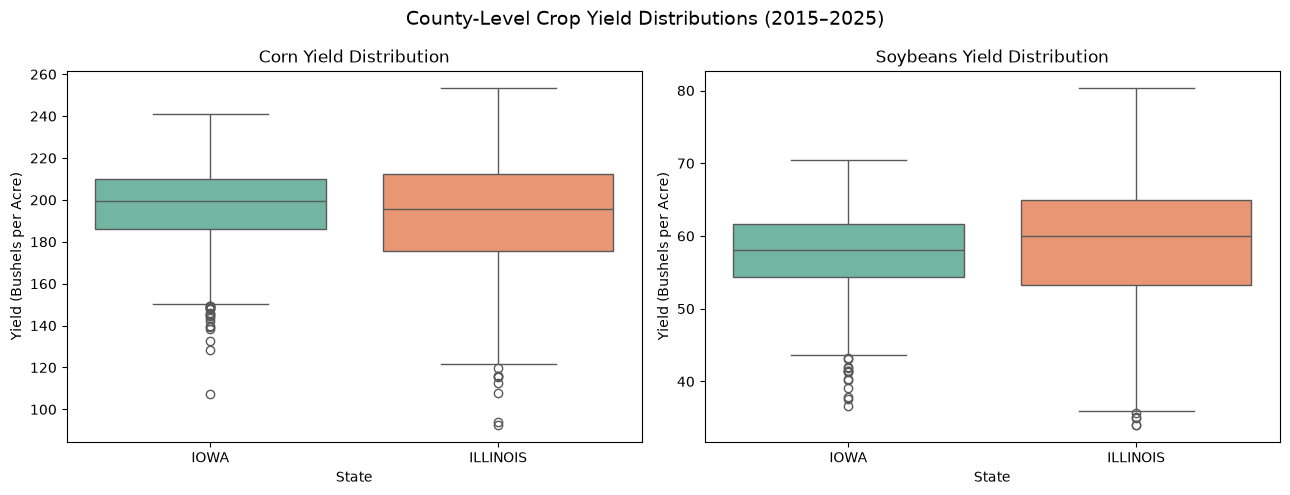

In [27]:
# Determine the crops and reporting years in the cleaned dataset
crops = sorted(clean_df["COMMODITY_DESC"].unique())
start_year = clean_df["YEAR"].min()
end_year = clean_df["YEAR"].max()

# Create one subplot per crop
fig, axes = plt.subplots(
    1,
    len(crops),
    figsize=(6.5 * len(crops), 5),
    squeeze=False
)

for ax, crop in zip(axes.flat, crops):
    subset = clean_df[
        clean_df["COMMODITY_DESC"] == crop
    ]

    sns.boxplot(
        data=subset,
        x="STATE_NAME",
        y="YIELD",
        hue="STATE_NAME",
        palette="Set2",
        legend=False,
        ax=ax
    )

    ax.set_title(f"{crop.title()} Yield Distribution")
    ax.set_xlabel("State")
    ax.set_ylabel("Yield (Bushels per Acre)")

plt.suptitle(
    f"County-Level Crop Yield Distributions ({start_year}–{end_year})",
    fontsize=14
)

plt.tight_layout()
plt.show()

These boxplots summarize the distribution of reported county-level yields across the study period. Differences in medians and variability can help identify patterns worth investigating further.

Because the plots combine observations from multiple years, they describe the overall distribution of available county-year records rather than yield differences in any single year. Additionally, counties with more reported years contribute more observations to the distributions.

We will examine temporal patterns separately to better understand how agricultural productivity changes over time.

### Temporal Trends in Crop Yields

While the boxplots reveal differences in yield distributions between geographic regions, they do not show how agricultural productivity changes over time.

To examine temporal patterns, we calculate the average reported county-level yield for each crop, state, and year within our selected study period. Visualizing these annual averages may reveal periods of unusually high or low productivity and help identify years that warrant further investigation.

These trends will also provide a foundation for examining potential relationships between agricultural yields and environmental conditions, including precipitation and temperature.

Because these averages are calculated from available county observations rather than weighted by harvested acreage, they should not be interpreted as official statewide yield estimates. Changes in county reporting coverage between years may also influence the observed averages.

In [28]:
annual_yields = (
    clean_df
    .groupby(["YEAR", "STATE_NAME", "COMMODITY_DESC"])["YIELD"]
    .mean()
    .reset_index()
)

display(annual_yields.head(10))

,YEAR,STATE_NAME,COMMODITY_DESC,YIELD
0,2015,ILLINOIS,CORN,172.541758
1,2015,ILLINOIS,SOYBEANS,54.970968
2,2015,IOWA,CORN,188.171579
3,2015,IOWA,SOYBEANS,55.653608
4,2016,ILLINOIS,CORN,184.298913
5,2016,ILLINOIS,SOYBEANS,57.65914
6,2016,IOWA,CORN,200.142424
7,2016,IOWA,SOYBEANS,59.386869
8,2017,ILLINOIS,CORN,191.322449
9,2017,ILLINOIS,SOYBEANS,56.635052


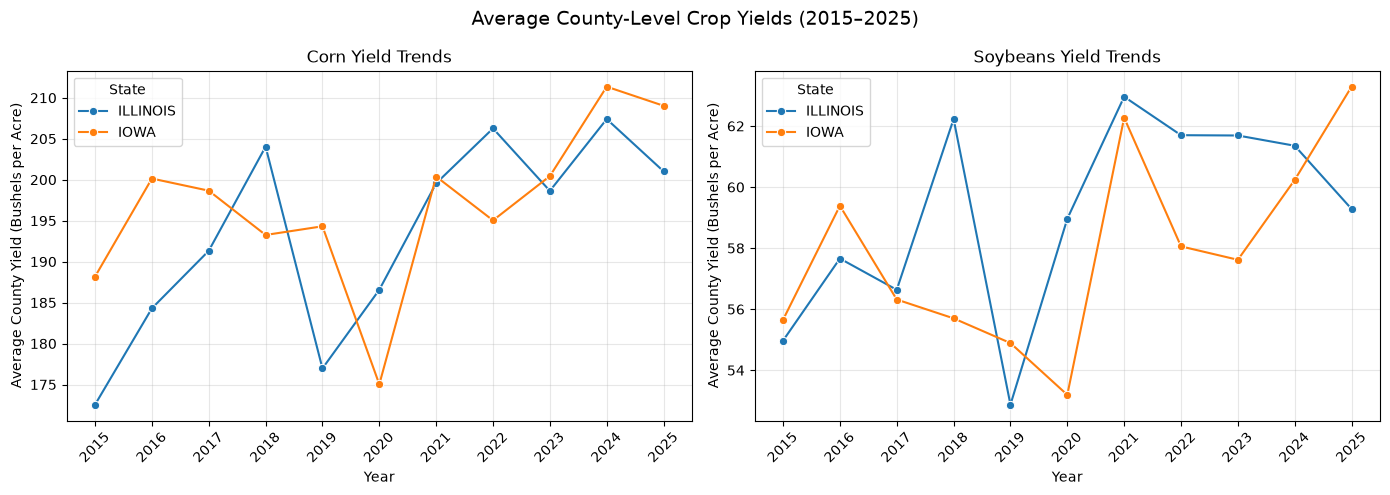

In [29]:
# Identify crops and years in the annual yield data
crops = sorted(annual_yields["COMMODITY_DESC"].unique())
years = sorted(annual_yields["YEAR"].unique())

# Create one subplot per crop
fig, axes = plt.subplots(
    1,
    len(crops),
    figsize=(7 * len(crops), 5),
    squeeze=False
)

for ax, crop in zip(axes.flat, crops):
    subset = annual_yields[
        annual_yields["COMMODITY_DESC"] == crop
    ]

    sns.lineplot(
        data=subset,
        x="YEAR",
        y="YIELD",
        hue="STATE_NAME",
        marker="o",
        estimator=None,
        ax=ax
    )

    ax.set_title(f"{crop.title()} Yield Trends")
    ax.set_xlabel("Year")
    ax.set_ylabel("Average County Yield (Bushels per Acre)")
    ax.set_xticks(years)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title="State")
    ax.grid(alpha=0.3)

plt.suptitle(
    f"Average County-Level Crop Yields ({min(years)}–{max(years)})",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Evaluating County Coverage Across Years

Annual average yields may be influenced by changes in the number of counties represented in the dataset. If different counties contribute observations in different years, changes in the calculated averages may reflect both agricultural conditions and differences in data coverage.

To assess this limitation, we examine the number of unique counties with reported yields for each crop, state, and year within our selected study period.

This analysis will help determine whether our temporal comparisons are based on reasonably consistent geographic coverage and identify potential limitations associated with missing county-year observations.

Because the number of reporting counties may differ between crops and years, we will consider these differences when interpreting trends and investigating relationships with environmental data.

In [30]:

# Count reporting counties by year, state, and crop
county_coverage = (
    clean_df
    .groupby(["YEAR", "STATE_NAME", "COMMODITY_DESC"])
    .agg(
        reporting_counties=("COUNTY_ANSI", "nunique"),
        observations=("YIELD", "count")
    )
    .reset_index()
)

display(county_coverage)


,YEAR,STATE_NAME,COMMODITY_DESC,reporting_counties,observations
0,2015,ILLINOIS,CORN,91,91
1,2015,ILLINOIS,SOYBEANS,93,93
2,2015,IOWA,CORN,95,95
3,2015,IOWA,SOYBEANS,97,97
4,2016,ILLINOIS,CORN,92,92
5,2016,ILLINOIS,SOYBEANS,93,93
6,2016,IOWA,CORN,99,99
7,2016,IOWA,SOYBEANS,99,99
8,2017,ILLINOIS,CORN,98,98
9,2017,ILLINOIS,SOYBEANS,97,97


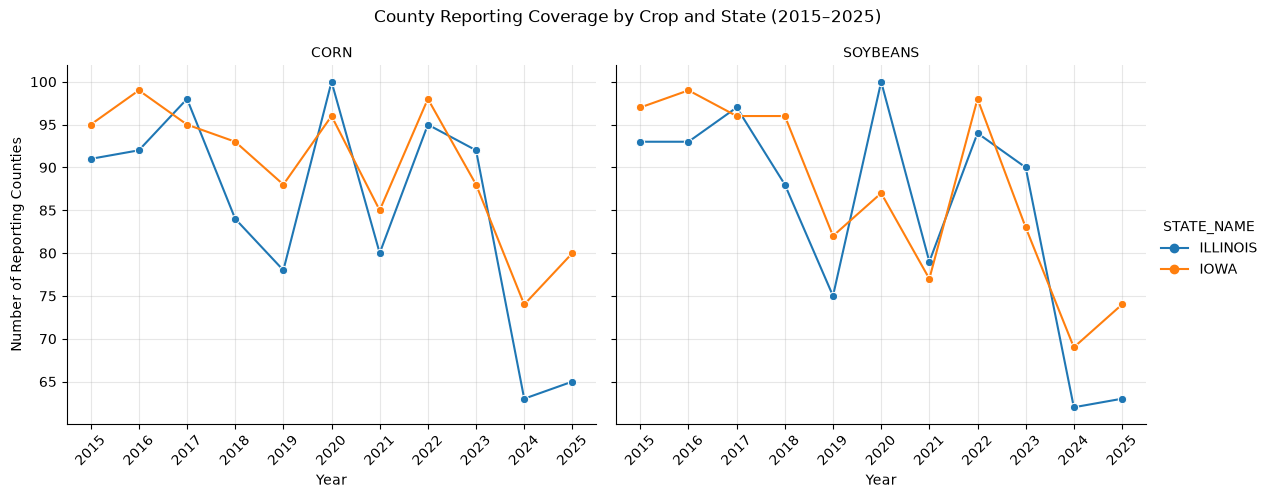

In [31]:
# Visualize county reporting coverage by crop and state
g = sns.relplot(
    data=county_coverage,
    x="YEAR",
    y="reporting_counties",
    hue="STATE_NAME",
    col="COMMODITY_DESC",
    kind="line",
    marker="o",
    facet_kws={"sharey": True},
    height=4.5,
    aspect=1.3
)

g.set_axis_labels("Year", "Number of Reporting Counties")
g.set_titles("{col_name}")
g.fig.suptitle(
    "County Reporting Coverage by Crop and State (2015–2025)",
    y=1.05
)

for ax in g.axes.flat:
    ax.set_xticks(sorted(county_coverage["YEAR"].unique()))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)

plt.show()


### Interpreting County Reporting Coverage

County reporting coverage varies considerably across the 2015–2025 study period. Although many state-crop combinations include approximately 80–100 reporting counties in earlier years, coverage declines noticeably in 2024 and remains relatively low in 2025.

The decline is particularly pronounced in Illinois, where corn reporting decreased from 92 counties in 2023 to 63 in 2024, while soybean reporting decreased from 90 to 62 counties over the same period.

These differences are important because changes in the composition of reporting counties may influence annual average yields. An increase or decrease in average yield does not necessarily reflect changes in agricultural productivity alone if different counties contribute observations each year.

The reporting data do not establish why particular counties are absent. Missing observations may reflect survey coverage, data suppression, publication timing, or other reporting factors.

For subsequent analysis, we will retain all available county-year observations while considering a balanced-panel comparison restricted to counties with complete reporting histories. This will help assess whether changes in reporting coverage influence our findings.

These counts represent counties with available yield observations, not the proportion of agricultural acreage represented.

### Assessing Longitudinal Data Completeness

The county coverage analysis revealed variation in the number of reporting counties across years. These differences may affect the interpretation of annual average yields because changes in the geographic composition of the dataset can influence the calculated averages.

To evaluate the feasibility of consistent longitudinal comparisons, we identify counties with yield observations for every year in our selected study period, separately for each crop and state.

A **balanced panel** contains the same geographic units observed across every year of the study period. This allows us to examine temporal changes without introducing variation caused by counties entering or leaving the dataset.

However, restricting the analysis to counties with complete reporting histories may substantially reduce the sample size and introduce selection bias if consistently reporting counties differ systematically from those with incomplete records.

We will therefore retain the full cleaned dataset while evaluating whether a balanced panel would be useful for subsequent analysis.

In [32]:
# Calculate the number of years in the configured study period
expected_years = (
    STUDY_CONFIG["end_year"]
    - STUDY_CONFIG["start_year"]
    + 1
)

# Count distinct reporting years for each county and crop
county_year_counts = (
    clean_df
    .groupby([
        "STATE_ANSI",
        "COUNTY_ANSI",
        "STATE_NAME",
        "COMMODITY_DESC"
    ])["YEAR"]
    .nunique()
    .reset_index(name="YEARS_REPORTED")
)

# Identify counties reporting in every year of the study period
complete_counties = county_year_counts[
    county_year_counts["YEARS_REPORTED"] == expected_years
].copy()

# Summarize complete county coverage by state and crop
complete_summary = (
    complete_counties
    .groupby(["STATE_NAME", "COMMODITY_DESC"])
    .size()
    .reset_index(name="COMPLETE_COUNTIES")
)

print(f"Expected reporting years: {expected_years}")
display(complete_summary)

Expected reporting years: 11


,STATE_NAME,COMMODITY_DESC,COMPLETE_COUNTIES
0,ILLINOIS,CORN,30
1,ILLINOIS,SOYBEANS,28
2,IOWA,CORN,43
3,IOWA,SOYBEANS,35


### Distribution of Reporting Years by County

The longitudinal completeness assessment allows us to evaluate how consistently individual counties report crop yields throughout the selected study period.

Restricting the analysis to counties with complete reporting histories may substantially reduce geographic coverage and introduce selection bias. We therefore retain counties with incomplete reporting histories in our primary dataset while investigating the extent of missing observations.

To better understand reporting completeness, we examine the distribution of the number of years reported by each county, separately for each crop and state.

This visualization helps distinguish counties with relatively complete reporting histories from those with substantial gaps. These findings will inform our approach to longitudinal comparisons and integration with environmental data.

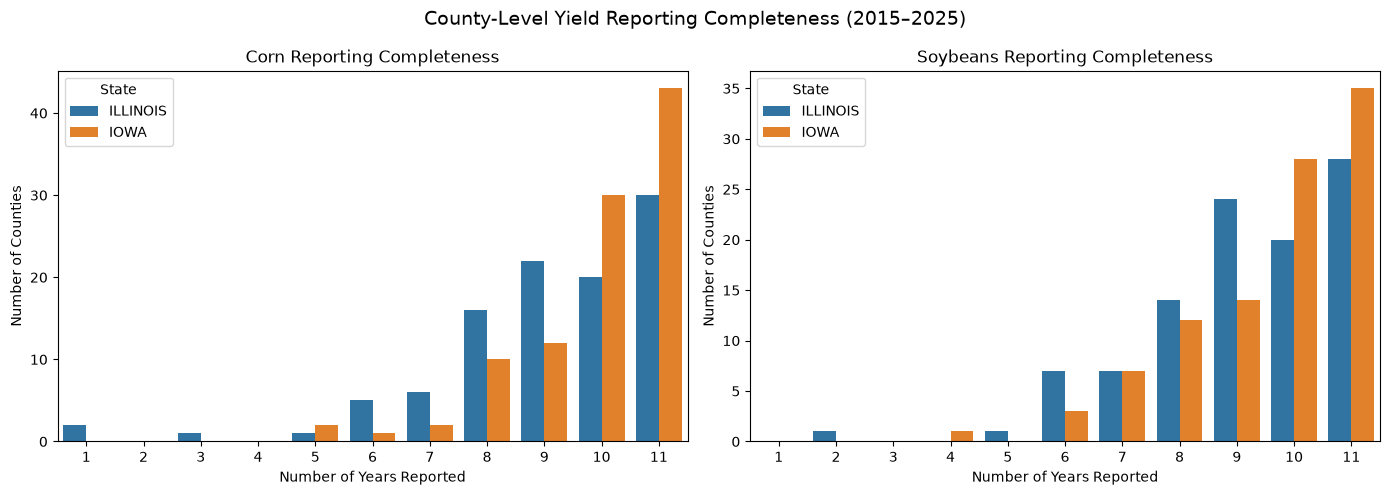

In [33]:
# Count counties by number of reporting years, state, and crop
reporting_distribution = (
    county_year_counts
    .groupby(["STATE_NAME", "COMMODITY_DESC", "YEARS_REPORTED"])
    .size()
    .reset_index(name="COUNTIES")
)

# Identify crops and expected reporting years
crops = sorted(reporting_distribution["COMMODITY_DESC"].unique())

expected_years = (
    STUDY_CONFIG["end_year"]
    - STUDY_CONFIG["start_year"]
    + 1
)

# Create one subplot per crop
fig, axes = plt.subplots(
    1,
    len(crops),
    figsize=(7 * len(crops), 5),
    squeeze=False
)

for ax, crop in zip(axes.flat, crops):
    subset = reporting_distribution[
        reporting_distribution["COMMODITY_DESC"] == crop
    ]

    sns.barplot(
        data=subset,
        x="YEARS_REPORTED",
        y="COUNTIES",
        hue="STATE_NAME",
        order=list(range(1, expected_years + 1)),
        ax=ax
    )

    ax.set_title(f"{crop.title()} Reporting Completeness")
    ax.set_xlabel("Number of Years Reported")
    ax.set_ylabel("Number of Counties")
    ax.legend(title="State")

plt.suptitle(
    f"County-Level Yield Reporting Completeness "
    f"({STUDY_CONFIG['start_year']}–{STUDY_CONFIG['end_year']})",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Interpretation of County-Level Reporting Completeness

The purpose of this analysis is to evaluate how consistently individual counties report corn and soybean yields between 2015 and 2025. This is important because our earlier visualizations calculated annual average yields using all available county observations. However, the number of reporting counties changes from year to year, potentially affecting comparisons of agricultural productivity over time.

The results show that most counties have relatively complete reporting histories, although gaps are present in both states and for both crops. Iowa generally demonstrates greater reporting consistency, with 43 counties reporting corn yields and 35 reporting soybean yields for all 11 years. Illinois has 30 counties with complete corn records and 28 with complete soybean records. Some counties have substantially fewer observations, particularly in Illinois.

These findings highlight an important limitation of our annual yield comparisons. For example, an increase in average yield between two years does not necessarily indicate that agricultural productivity improved across the state. It could partially reflect changes in which counties contributed data. If lower-yielding counties are absent in a particular year, the calculated average may increase even if yields in the remaining counties have not changed.

**Implications for Our Research**

Our primary objective is to investigate relationships between environmental conditions and agricultural productivity, rather than simply comparing statewide average yields. For this reason, we will retain all 3,821 cleaned county-level observations instead of restricting the dataset to counties with complete 11-year histories.

When integrating NASA environmental data, we plan to associate climate measurements with agricultural yields by county and year. This will allow us to investigate how temperature and precipitation relate to crop productivity within specific geographic areas. Additional environmental variables may be considered depending on data availability and suitability.

Retaining counties with incomplete reporting histories creates an **unbalanced panel**, in which different counties may contribute observations in different years. This approach preserves greater geographic coverage and more available observations, but it does not eliminate the potential influence of missing data.

In subsequent analyses, we will consider differences in county coverage, investigate appropriate statistical methods for longitudinal data, and avoid treating unweighted averages of reporting counties as official statewide yield estimates.

In [ ]:
from pathlib import Path

# Create the processed data directory if it doesn't exist
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Export cleaned USDA crop yield data
USDA_DATA_PATH = PROCESSED_DIR / "USDA_Crop_Yields_Cleaned.csv"

clean_df.to_csv(
    USDA_DATA_PATH,
    index=False
)

print(f"Saved {len(clean_df):,} records to {USDA_DATA_PATH}")